In [1]:
import os
import zipfile
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

Device: cuda


In [2]:
from google.colab import drive
drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/fungi_dataset.zip'
extract_dir = '/content/mendeley_dataset'

if not os.path.exists(extract_dir):
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(extract_dir)
print("Dataset extracted to:", extract_dir)

Mounted at /content/drive
Dataset extracted to: /content/mendeley_dataset


In [3]:
# Standard Hyperparameters
img_size = 64
batch_size = 64
learning_rate = 0.001
minimum_learning_rate = 1e-4
dropout_rate = 0.5
epochs = 20

In [4]:
train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor()
])

# Auto-detect train/test folders or create an 80/20 split
train_folder, test_folder = None, None
for root, dirs, _ in os.walk(extract_dir):
    dmap = {d.lower(): d for d in dirs}
    if 'train' in dmap and ('test' in dmap or 'validation' in dmap or 'val' in dmap):
        train_folder = os.path.join(root, dmap['train'])
        test_key = 'test' if 'test' in dmap else ('validation' if 'validation' in dmap else 'val')
        test_folder = os.path.join(root, dmap[test_key])
        break

if train_folder and test_folder:
    train_data = datasets.ImageFolder(train_folder, transform=train_transform)
    test_data = datasets.ImageFolder(test_folder, transform=val_transform)
    class_names = train_data.classes
else:
    class_root = None
    for root, dirs, _ in os.walk(extract_dir):
        valid = [d for d in dirs if not d.startswith(('.', '__')) and any(
            f.lower().endswith(('.jpg', '.jpeg', '.png')) for f in os.listdir(os.path.join(root, d))
        )]
        if len(valid) >= 2:
            class_root = root
            break
    full_train = datasets.ImageFolder(class_root, transform=train_transform)
    full_test = datasets.ImageFolder(class_root, transform=val_transform)
    class_names = full_train.classes
    idx = np.arange(len(full_train))
    tr_idx, te_idx = train_test_split(idx, test_size=0.2, random_state=42, stratify=full_train.targets)
    train_data = Subset(full_train, tr_idx)
    test_data = Subset(full_test, te_idx)

num_classes = len(class_names)
print(f"Classes ({num_classes}): {class_names}")
print(f"Trn: {len(train_data)}")
print(f"Tst: {len(test_data)}")

Classes (5): ['H1', 'H2', 'H3', 'H5', 'H6']
Trn: 5000
Tst: 902


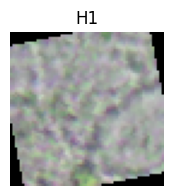

In [5]:
plt.figure(figsize=(2, 2))
img, lbl = train_data[0]
plt.imshow(img.permute(1, 2, 0))
plt.title(class_names[lbl])
plt.axis('off')
plt.show()

In [6]:
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

In [7]:
class CNNModel(nn.Module):
    def __init__(self, num_classes):
        super(CNNModel, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3),   # 3x64x64 -> 64x62x62
            nn.MaxPool2d(2),                   # 64x31x31
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3), # 128x29x29
            nn.MaxPool2d(2),                   # 128x14x14
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3),# 128x12x12
            nn.MaxPool2d(2),                   # 128x6x6
            nn.ReLU()
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 6 * 6, 256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

model = CNNModel(num_classes=num_classes).to(device)
optimizer = Adam(model.parameters(), lr=learning_rate)
scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=minimum_learning_rate)
criterion = nn.CrossEntropyLoss()

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {trainable_params:,}")

from torchsummary import summary
summary(model, input_size=(3, img_size, img_size))

Total Trainable Parameters: 1,404,421
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
         MaxPool2d-2           [-1, 64, 31, 31]               0
              ReLU-3           [-1, 64, 31, 31]               0
            Conv2d-4          [-1, 128, 29, 29]          73,856
         MaxPool2d-5          [-1, 128, 14, 14]               0
              ReLU-6          [-1, 128, 14, 14]               0
            Conv2d-7          [-1, 128, 12, 12]         147,584
         MaxPool2d-8            [-1, 128, 6, 6]               0
              ReLU-9            [-1, 128, 6, 6]               0
          Flatten-10                 [-1, 4608]               0
           Linear-11                  [-1, 256]       1,179,904
             ReLU-12                  [-1, 256]               0
          Dropout-13                  [-1, 256]               0
 

In [8]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(loader)
    train_acc = correct / total
    return train_loss, train_acc

def validate_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    val_loss = total_loss / len(loader)
    val_acc = correct / total
    return val_loss, val_acc

In [9]:
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

best_val_acc = 0.0
best_val_loss = float('inf')

for epoch in range(epochs):
    print("----------------------------------------------------")
    print(f"Epoch {epoch+1}/{epochs}, LR: {optimizer.param_groups[0]['lr']:.6g}")

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
    scheduler.step()

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
    if val_loss < best_val_loss:
        best_val_loss = val_loss

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

----------------------------------------------------
Epoch 1/20, LR: 0.001
Train Loss: 1.4380 | Train Acc: 0.3464
Val Loss: 1.2636 | Val Acc: 0.5798
----------------------------------------------------
Epoch 2/20, LR: 0.00099446
Train Loss: 1.3206 | Train Acc: 0.4248
Val Loss: 1.0853 | Val Acc: 0.5965
----------------------------------------------------
Epoch 3/20, LR: 0.000977975
Train Loss: 1.2387 | Train Acc: 0.4652
Val Loss: 1.0179 | Val Acc: 0.6020
----------------------------------------------------
Epoch 4/20, LR: 0.000950953
Train Loss: 1.1626 | Train Acc: 0.5126
Val Loss: 1.1036 | Val Acc: 0.5965
----------------------------------------------------
Epoch 5/20, LR: 0.000914058
Train Loss: 1.1115 | Train Acc: 0.5434
Val Loss: 1.0515 | Val Acc: 0.5987
----------------------------------------------------
Epoch 6/20, LR: 0.000868198
Train Loss: 1.0921 | Train Acc: 0.5434
Val Loss: 0.9416 | Val Acc: 0.6530
----------------------------------------------------
Epoch 7/20, LR: 0.000814

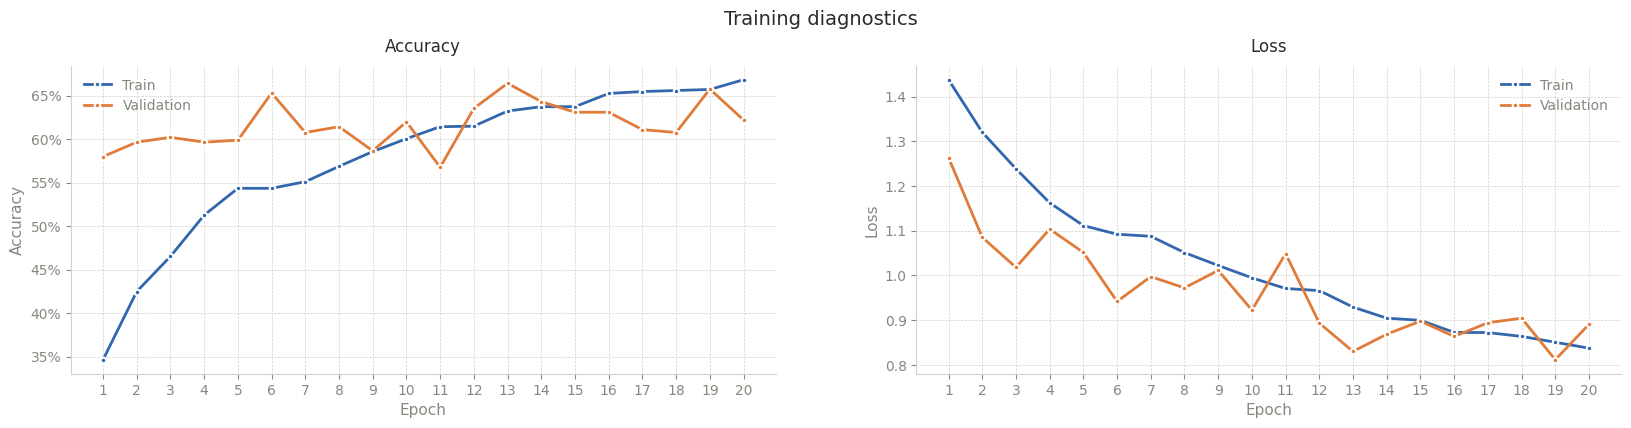

In [10]:
BLUE   = "#3266ad"
ORANGE = "#e07b39"
GRAY   = "#88877f"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#d3d1c7",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": "#d3d1c7",
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

epochs_number = np.arange(1, epochs + 1)
fig = plt.figure(figsize=(20, 4))
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.2)

ax1 = fig.add_subplot(gs[0])
ax1.plot(epochs_number, train_accuracies, color=BLUE,   lw=2, label="Train",      marker="o", ms=4, mew=1.5, mec="white")
ax1.plot(epochs_number, val_accuracies,   color=ORANGE, lw=2, label="Validation", marker="o", ms=4, mew=1.5, mec="white")
ax1.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%"))
ax1.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax1.set_ylabel("Accuracy", color=GRAY, fontsize=11)
ax1.set_title("Accuracy", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10)
ax1.legend(frameon=False, fontsize=10, labelcolor=GRAY)

ax2 = fig.add_subplot(gs[1])
ax2.plot(epochs_number, train_losses, color=BLUE,   lw=2, label="Train",      marker="o", ms=4, mew=1.5, mec="white")
ax2.plot(epochs_number, val_losses,   color=ORANGE, lw=2, label="Validation", marker="o", ms=4, mew=1.5, mec="white")
ax2.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax2.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax2.set_ylabel("Loss",  color=GRAY, fontsize=11)
ax2.set_title("Loss", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10)
ax2.legend(frameon=False, fontsize=10, labelcolor=GRAY)

fig.suptitle("Training diagnostics", fontsize=14, fontweight="medium", color="#2c2c2a", y=1.02)
plt.savefig("training_curves.pdf", bbox_inches="tight", dpi=150)
plt.show()

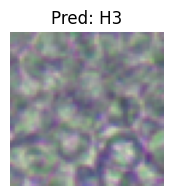

In [11]:
model.eval()
ix = torch.randint(0, len(test_data), ()).item()
img = test_data[ix][0].unsqueeze(0).to(device)
with torch.no_grad():
    np_output = model(img).cpu().numpy()
pred = np.exp(np_output) / np.sum(np.exp(np_output))

plt.figure(figsize=(2, 2))
plt.imshow(img.squeeze(0).permute(1, 2, 0).cpu().numpy())
plt.title(f"Pred: {class_names[pred[0].argmax()]}")
plt.axis('off')
plt.show()

Classification Report:

              precision    recall  f1-score   support

          H1       0.79      0.70      0.74       437
          H2       0.52      0.30      0.38       233
          H3       0.28      0.73      0.40        82
          H5       0.74      0.78      0.76        80
          H6       0.77      0.93      0.84        70

    accuracy                           0.62       902
   macro avg       0.62      0.69      0.62       902
weighted avg       0.67      0.62      0.63       902



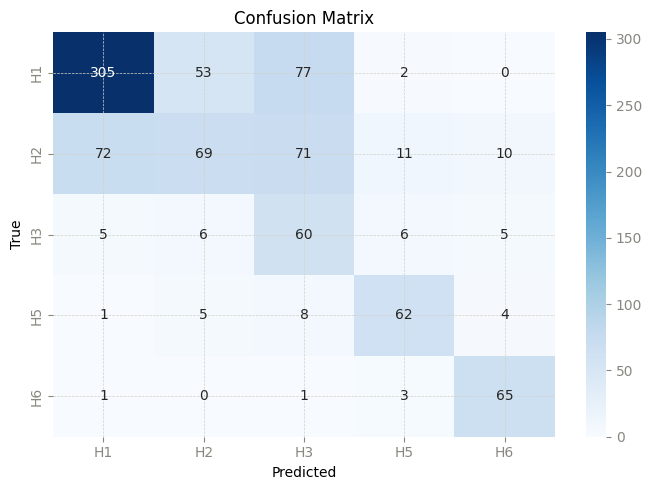

Total misclassified samples: 341


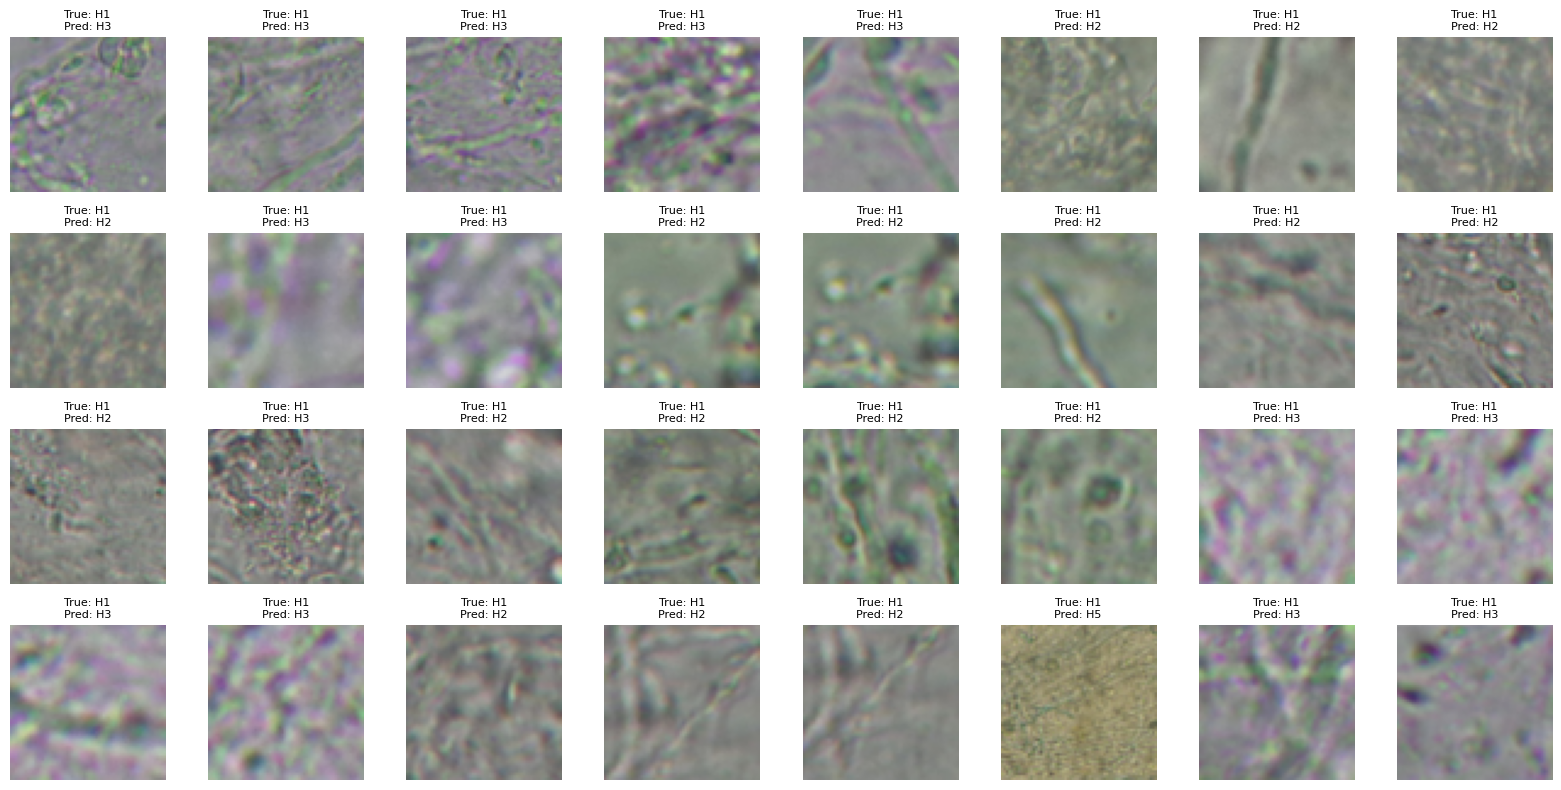

In [12]:
model.eval()
misclassified = []
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        for img, true, pred in zip(images, labels, preds):
            if true != pred:
                misclassified.append((img.cpu(), true.cpu().item(), pred.cpu().item()))

print("Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

print(f"Total misclassified samples: {len(misclassified)}")

num_rows = 4
num_cols = 8
num_to_show = min(num_rows * num_cols, len(misclassified))

if num_to_show > 0:
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 2, num_rows * 2))
    axes = axes.flatten()

    for idx in range(num_to_show):
        img, true, pred = misclassified[idx]
        img = (img.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
        axes[idx].imshow(img)
        axes[idx].set_title(f"True: {class_names[true]}\nPred: {class_names[pred]}", fontsize=8)
        axes[idx].axis('off')

    for idx in range(num_to_show, len(axes)):
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

In [13]:
print("=== SUBMISSION FORM SUMMARY ===")
print("Student ID:", "23-52793-2")
print("Student Name:", "Md Al-Akhiruzzaman Dorpan")
print("Section:", "D")
print("Dataset Name:", "Fungi MultiClass Microscopic Fungi Images")
print("Dataset Description:", "Multi-class microscopic fungi image dataset with 6,801 images across 5 classes.")
print("Number of Classes:", num_classes)
print("Dataset Link:", "https://data.mendeley.com/datasets/4g9yhrtsy5")
print("Training Images:", len(train_data))
print("Testing Images:", len(test_data))
print(f"Best Accuracy (%): {best_val_acc * 100:.2f}")
print(f"Best Loss: {best_val_loss:.4f}")
print("Epochs Trained:", epochs)
print("Regularization: Dropout in Neural Networks")
print("Learning Rate:", learning_rate)
print("Total Trainable Parameters:", trainable_params)

=== SUBMISSION FORM SUMMARY ===
Student ID: 23-52793-2
Student Name: Md Al-Akhiruzzaman Dorpan
Section: D
Dataset Name: Fungi MultiClass Microscopic Fungi Images
Dataset Description: Multi-class microscopic fungi image dataset with 6,801 images across 5 classes.
Number of Classes: 5
Dataset Link: https://data.mendeley.com/datasets/4g9yhrtsy5
Training Images: 5000
Testing Images: 902
Best Accuracy (%): 66.41
Best Loss: 0.8112
Epochs Trained: 20
Regularization: Dropout in Neural Networks
Learning Rate: 0.001
Total Trainable Parameters: 1404421
